# Lab 2 — Ciclo de treino, vazamento e métricas
**Individual · 1,0 ponto na AV1 · 08/10/2026 · horário da atividade no Classroom**

Leia `ENUNCIADO.pdf` antes de preencher. A base comum está incluída; não é necessário usar o banco do projeto.

O notebook executa a preparação e um teste pequeno de ambiente. Nas atividades avaliadas, complete os **TODO** e substitua as mensagens de pendência por resultados. Não há métricas pré-medidas para copiar.

Ordem: preparação → B2 → A → C → D7 → D4–D6 → avaliação final → relatório.

## 0. Ambiente e pasta
No Colab, extraia o ZIP conforme o enunciado e execute `%cd /content/classroom-lab-02` antes da próxima célula. Localmente, abra este notebook na pasta extraída. CPU é suficiente.

In [1]:
from pathlib import Path
import sys, copy, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))

Python: 3.11.4
numpy 2.4.6
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.14.1


### Leitura e conferência da base
`carregar_base` lê o CSV com `;`, confere sua integridade e cria o alvo e os identificadores de controle. As únicas entradas permitidas estão em `FEATURES`. Não aprende média, desvio, pesos ou partições.

Ver as contagens do arquivo não é treinar um modelo. Depois da B2, o teste principal deve permanecer fora das decisões e dos experimentos de erro.

In [2]:
base = carregar_base()
print(base.head().to_string(index=False))
print('\nLinhas:', len(base), '| características:', len(FEATURES))
print('Classe positiva:', int(base.alvo.sum()), '| proporção:', base.alvo.mean())
print('Perfis distintos:', base.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo: o que faz uma atualização
O bloco a seguir usa **quatro observações artificiais com duas entradas**, apenas para conferir instalação e formas. Não usa Wine Quality, não mede generalização e não atende às partes avaliadas. Um logit é transformado em escore por sigmoide só ao obter previsões; a perda recebe o logit.

In [3]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297777175903


## B2. Separe antes de normalizar
Implemente aproximadamente 60/20/20, conservando `grupo_perfil` em uma única partição. Use uma semente declarada. Consulte `GroupShuffleSplit`; proporções de grupos não garantem as mesmas proporções de linhas.

Retorne um dicionário com `treino`, `validacao`, `teste`, cada qual contendo um DataFrame. Mostre cobertura, interseção de linhas e perfis, contagens e classes. Não use IDs como características.

In [4]:
from sklearn.model_selection import GroupShuffleSplit

def particionar_sem_vazar(df, semente=42):
    """Divide df em treino/validação/teste (~60/20/20) mantendo cada grupo_perfil
    inteiro em uma única partição.

    Regra: perfis com as 11 características idênticas ficam juntos, para que o
    modelo nunca seja avaliado numa configuração que já viu no treino.
    O alvo NÃO é usado na divisão (apenas os grupos), e a semente é fixa.
    """
    grupos = df['grupo_perfil']

    # Etapa 1: reservar ~20% dos GRUPOS para o teste (fica trancado até a Parte D)
    gss_teste = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semente)
    idx_dev, idx_teste = next(gss_teste.split(df, groups=grupos))
    desenvolvimento = df.iloc[idx_dev]
    teste = df.iloc[idx_teste]

    # Etapa 2: dentro do desenvolvimento, 25% dos grupos vão para validação
    # (0,25 x 0,80 = 0,20 do total; o restante, ~60%, é treino)
    gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=semente)
    idx_tr, idx_val = next(gss_val.split(desenvolvimento,
                                         groups=desenvolvimento['grupo_perfil']))
    treino = desenvolvimento.iloc[idx_tr]
    validacao = desenvolvimento.iloc[idx_val]

    # reset_index: numeração 0..n-1 em cada partição (útil no Dataset);
    # a identidade original continua preservada na coluna id_linha
    return {
        'treino': treino.reset_index(drop=True).copy(),
        'validacao': validacao.reset_index(drop=True).copy(),
        'teste': teste.reset_index(drop=True).copy(),
    }

particoes = particionar_sem_vazar(base, SEED)

# Conferência rápida de tamanhos (a auditoria completa vem no próximo bloco)
for nome, parte in particoes.items():
    print(f"{nome:10s} linhas={len(parte):5d}  ({len(parte)/len(base):.1%} da base)")

treino     linhas=  961  (60.1% da base)
validacao  linhas=  318  (19.9% da base)
teste      linhas=  320  (20.0% da base)


### Auditoria da partição

É a “conferência de caixa” da divisão. Não basta dizer que separou certo: é preciso mostrar com números que nenhuma linha se perdeu, nenhuma foi duplicada e nenhum perfil aparece em dois conjuntos ao mesmo tempo. O enunciado avisa que índices diferentes não garantem características diferentes. Por isso verificamos as duas coisas: id_linha e grupo_perfil.

In [5]:
from itertools import combinations

# 1) Tabela por conjunto: linhas, positivos, proporção positiva e perfis distintos
auditoria_b2 = pd.DataFrame([
    {'conjunto': nome,
     'linhas': len(p),
     'positivos': int(p['alvo'].sum()),
     'proporcao_positiva': round(p['alvo'].mean(), 4),
     'perfis': p['grupo_perfil'].nunique()}
    for nome, p in particoes.items()
])
print(auditoria_b2.to_string(index=False))

# 2) Cobertura: todas as linhas da base aparecem exatamente uma vez
ids_todos = pd.concat([p['id_linha'] for p in particoes.values()])
print('\nSoma das linhas:', len(ids_todos), '| linhas na base:', len(base))
print('IDs únicos nas partições:', ids_todos.nunique())
print('Cobertura completa:', set(ids_todos) == set(base['id_linha']))
print('Soma dos perfis:', auditoria_b2['perfis'].sum(),
      '| perfis distintos na base:', base['grupo_perfil'].nunique())

# 3) Interseções par a par: linhas e perfis em comum (devem ser zero)
print()
for a, b in combinations(particoes, 2):
    linhas_comuns = len(set(particoes[a]['id_linha']) & set(particoes[b]['id_linha']))
    perfis_comuns = len(set(particoes[a]['grupo_perfil']) & set(particoes[b]['grupo_perfil']))
    print(f'{a} x {b}: linhas em comum = {linhas_comuns} | perfis em comum = {perfis_comuns}')
    assert linhas_comuns == 0 and perfis_comuns == 0, 'Vazamento entre partições!'

# 4) Ambas as classes presentes em cada conjunto
for nome, p in particoes.items():
    assert set(p['alvo'].unique()) == {0, 1}, f'{nome} não tem as duas classes'

# 5) Salvar a tabela para o README
auditoria_b2.to_csv(RESULTADOS / 'b2_auditoria.csv', index=False)
print('\nAuditoria aprovada. Tabela salva em resultados/b2_auditoria.csv')

 conjunto  linhas  positivos  proporcao_positiva  perfis
   treino     961        139              0.1446     815
validacao     318         33              0.1038     272
    teste     320         45              0.1406     272

Soma das linhas: 1599 | linhas na base: 1599
IDs únicos nas partições: 1599
Cobertura completa: True
Soma dos perfis: 1359 | perfis distintos na base: 1359

treino x validacao: linhas em comum = 0 | perfis em comum = 0
treino x teste: linhas em comum = 0 | perfis em comum = 0
validacao x teste: linhas em comum = 0 | perfis em comum = 0

Auditoria aprovada. Tabela salva em resultados/b2_auditoria.csv


### B1. Cinco cenários
Responda no README aos cinco cenários do enunciado: avaliações de produtos; turbinas; spam; radiografias; transações. Declare o uso e as hipóteses. Na quinta resposta, discuta tempo e identidade dos clientes. As respostas não precisam de bancos adicionais.

## A1. Dataset próprio
Implemente a classe abaixo com as estatísticas opcionais. Aprenda média/desvio somente no treino e passe-os aos outros conjuntos. Trate desvio zero, preserve o alinhamento e devolva `float32`: X `[11]`, y escalar. Mostre as verificações solicitadas.

In [6]:
class MeuDataset(Dataset):
    """Dataset tabular de uma única partição, com padronização z-score.

    As estatísticas (média e desvio) vêm de UMA das duas origens:
      - aprendidas neste conjunto, quando media e desvio são None (uso: TREINO);
      - recebidas prontas, quando informadas (uso: VALIDAÇÃO e TESTE, que
        reutilizam as do treino e nunca calculam as próprias).
    Convenção do desvio: populacional (ddof=0, divide por n).
    """

    def __init__(self, df, features, media=None, desvio=None):
        """Valida as entradas, define as estatísticas e prepara os tensores.

        df: DataFrame de uma partição, com as colunas de features e 'alvo'.
        features: lista das 11 colunas de entrada (não pode conter alvo/IDs).
        media, desvio: arrays de tamanho len(features), ou ambos None.
        """
        proibidas = {'quality', 'alvo', 'id_linha', 'grupo_perfil'}
        if set(features) & proibidas:
            raise ValueError('Features contém colunas proibidas (alvo ou identificadores).')
        if (media is None) != (desvio is None):
            raise ValueError('Informe media e desvio juntos, ou nenhum dos dois.')

        X = df[features].to_numpy(dtype=np.float64)   # float64 no cálculo, para precisão
        y = df['alvo'].to_numpy(dtype=np.float32)

        if media is None:
            # TREINO: aprende as estatísticas apenas com estas linhas
            media = X.mean(axis=0)
            desvio = X.std(axis=0, ddof=0)
            self.origem_estatisticas = 'aprendidas neste conjunto'
        else:
            # VALIDAÇÃO/TESTE: copia as estatísticas recebidas (copy evita alterações acidentais)
            media = np.array(media, dtype=np.float64, copy=True)
            desvio = np.array(desvio, dtype=np.float64, copy=True)
            self.origem_estatisticas = 'recebidas de outro conjunto'

        if media.shape != (len(features),) or desvio.shape != (len(features),):
            raise ValueError('media/desvio precisam ter um valor por feature.')

        # Desvio zero (ou quase): usa 1 para não dividir por zero; a coluna vira 0
        self.colunas_desvio_zero = [f for f, d in zip(features, desvio) if d < 1e-12]
        desvio_seguro = np.where(desvio < 1e-12, 1.0, desvio)

        X_norm = (X - media) / desvio_seguro
        if not np.isfinite(X_norm).all():
            raise ValueError('Normalização produziu NaN ou infinito.')

        # Guarda estatísticas (para repassar a outros conjuntos) e tensores alinhados
        self.features = list(features)
        self.media, self.desvio = media, desvio
        self.X = torch.tensor(X_norm, dtype=torch.float32)   # [n, 11]
        self.y = torch.tensor(y, dtype=torch.float32)        # [n]
        self.id_linha = df['id_linha'].to_numpy()            # só para auditoria, não entra no modelo

    def __len__(self):
        """Devolve o número de observações (linhas) da partição."""
        return len(self.y)

    def __getitem__(self, indice):
        """Devolve (X, y) da observação `indice`: X com forma [11] e y escalar, float32.
        X e y vêm da mesma posição, logo permanecem alinhados."""
        return self.X[indice], self.y[indice]


# Treino aprende; validação e teste recebem as estatísticas do treino
ds_treino = MeuDataset(particoes['treino'], FEATURES)
ds_validacao = MeuDataset(particoes['validacao'], FEATURES,
                          media=ds_treino.media, desvio=ds_treino.desvio)
ds_teste = MeuDataset(particoes['teste'], FEATURES,
                      media=ds_treino.media, desvio=ds_treino.desvio)

for nome, ds in [('treino', ds_treino), ('validacao', ds_validacao), ('teste', ds_teste)]:
    print(f'{nome:10s} len={len(ds):4d} | estatísticas: {ds.origem_estatisticas}')
print('Colunas com desvio zero no treino:', ds_treino.colunas_desvio_zero)

treino     len= 961 | estatísticas: aprendidas neste conjunto
validacao  len= 318 | estatísticas: recebidas de outro conjunto
teste      len= 320 | estatísticas: recebidas de outro conjunto
Colunas com desvio zero no treino: []


### Verificações

* Formas e tipos de um exemplo e de um lote;
* Ausência de NaN e infinito;
* Validação e teste usando as estatísticas do treino;
* Tratamento de desvio zero.

In [7]:
# 1) Um exemplo: X deve ter forma [11] e y forma [] (escalar), ambos float32
X0, y0 = ds_treino[0]
print('Exemplo -> X:', tuple(X0.shape), X0.dtype, '| y:', tuple(y0.shape), y0.dtype)

# 2) Um lote: DataLoader temporário só para verificar formas [B, 11] e [B]
_lote_x, _lote_y = next(iter(DataLoader(ds_treino, batch_size=8)))
print('Lote    -> X:', tuple(_lote_x.shape), _lote_x.dtype, '| y:', tuple(_lote_y.shape), _lote_y.dtype)
del _lote_x, _lote_y

# 3) Sem NaN/infinito em nenhum dos três conjuntos
for nome, ds in [('treino', ds_treino), ('validacao', ds_validacao), ('teste', ds_teste)]:
    print(f'{nome:10s} X finito: {bool(torch.isfinite(ds.X).all())} | '
          f'y só 0/1: {set(ds.y.unique().tolist()) <= {0.0, 1.0}}')

# 4) Evidência de que validação e teste usam as estatísticas DO TREINO
print('\nValidação usa média/desvio do treino:',
      np.array_equal(ds_validacao.media, ds_treino.media) and np.array_equal(ds_validacao.desvio, ds_treino.desvio))
print('Teste usa média/desvio do treino:',
      np.array_equal(ds_teste.media, ds_treino.media) and np.array_equal(ds_teste.desvio, ds_treino.desvio))
media_propria_val = particoes['validacao'][FEATURES].to_numpy().mean(axis=0)
print('Média própria da validação difere da do treino (prova de que não foi recalculada):',
      not np.allclose(media_propria_val, ds_treino.media))

# 5) Médias e desvios após normalizar: treino ~0/~1; validação/teste PRÓXIMOS, mas não exatamente
resumo = pd.DataFrame({
    'media_treino': ds_treino.X.mean(0).numpy(), 'desvio_treino': ds_treino.X.std(0, unbiased=False).numpy(),
    'media_valid': ds_validacao.X.mean(0).numpy(), 'media_teste': ds_teste.X.mean(0).numpy(),
}, index=FEATURES).round(3)
print('\n', resumo.to_string())

# 6) Alinhamento: recalcular à mão a linha 0 da validação e comparar com o Dataset
bruto = particoes['validacao'].loc[0, FEATURES].to_numpy(dtype=np.float64)
esperado = (bruto - ds_treino.media) / ds_treino.desvio
print('\nLinha 0 da validação confere com cálculo manual:',
      np.allclose(ds_validacao.X[0].numpy(), esperado, atol=1e-5),
      '| y confere:', float(ds_validacao.y[0]) == float(particoes['validacao'].loc[0, 'alvo']))

# 7) Desvio zero: teste artificial com uma coluna constante (não usa a base principal)
_df_const = particoes['treino'].head(5).copy()
_df_const['pH'] = 3.3
_ds_const = MeuDataset(_df_const, FEATURES)
print('Teste de desvio zero -> colunas detectadas:', _ds_const.colunas_desvio_zero,
      '| X finito:', bool(torch.isfinite(_ds_const.X).all()))
del _df_const, _ds_const

# 8) Salvar as estatísticas do treino (fazem parte da configuração congelada na Parte D)
pd.DataFrame({'media': ds_treino.media, 'desvio_ddof0': ds_treino.desvio},
             index=FEATURES).to_csv(RESULTADOS / 'a1_estatisticas_treino.csv')
print('Estatísticas do treino salvas em resultados/a1_estatisticas_treino.csv')

Exemplo -> X: (11,) torch.float32 | y: () torch.float32
Lote    -> X: (8, 11) torch.float32 | y: (8,) torch.float32
treino     X finito: True | y só 0/1: True
validacao  X finito: True | y só 0/1: True
teste      X finito: True | y só 0/1: True

Validação usa média/desvio do treino: True
Teste usa média/desvio do treino: True
Média própria da validação difere da do treino (prova de que não foi recalculada): True

                       media_treino  desvio_treino  media_valid  media_teste
fixed acidity                  0.0            1.0        0.091       -0.021
volatile acidity               0.0            1.0        0.134        0.016
citric acid                   -0.0            1.0        0.017       -0.009
residual sugar                -0.0            1.0       -0.009       -0.006
chlorides                      0.0            1.0        0.011       -0.033
free sulfur dioxide            0.0            1.0        0.104        0.103
total sulfur dioxide           0.0            1.0 

## A2. Três DataLoaders
Preencha a tabela de parâmetros no README e crie os carregadores. Na avaliação não descarte observações. `obter_escores` devolve rótulos e escores percorridos juntos, evitando confundir uma ordem de rótulos com outra de previsões.

In [8]:
# Configuração dos três carregadores (justificativas na tabela do README)
LOTE_TREINO = 64       # compromisso entre nº de atualizações por época e estabilidade
LOTE_AVALIACAO = 256   # sem gradientes: tamanho só afeta velocidade, não o resultado

gerador_treino = torch.Generator().manual_seed(SEED)   # embaralhamento reprodutível

loader_treino = DataLoader(ds_treino, batch_size=LOTE_TREINO, shuffle=True,
                           drop_last=True, num_workers=0, generator=gerador_treino)
loader_validacao = DataLoader(ds_validacao, batch_size=LOTE_AVALIACAO, shuffle=False,
                              drop_last=False, num_workers=0)
loader_teste = DataLoader(ds_teste, batch_size=LOTE_AVALIACAO, shuffle=False,
                          drop_last=False, num_workers=0)

# 1) Quantos lotes, quantas linhas usadas por época e o resto da divisão
tabela_a2 = []
for nome, ld in [('treino', loader_treino), ('validacao', loader_validacao), ('teste', loader_teste)]:
    n = len(ld.dataset)
    usadas = sum(len(y) for _, y in ld)        # percorre o loader e conta de fato
    tabela_a2.append({'conjunto': nome, 'linhas': n, 'batch_size': ld.batch_size,
                      'lotes_por_epoca': len(ld), 'resto': n % ld.batch_size,
                      'linhas_usadas_por_epoca': usadas, 'drop_last': ld.drop_last})
print(pd.DataFrame(tabela_a2).to_string(index=False))

# 2) Avaliação: nenhuma linha descartada
assert tabela_a2[1]['linhas_usadas_por_epoca'] == len(ds_validacao)
assert tabela_a2[2]['linhas_usadas_por_epoca'] == len(ds_teste)

# 3) Alinhamento: a ordem dos rótulos no loader de validação é a mesma do Dataset
y_loader_val = torch.cat([y for _, y in loader_validacao])
print('\nOrdem da validação preservada no loader:', torch.equal(y_loader_val, ds_validacao.y))

# 4) Treino: o embaralhamento muda a ordem entre épocas (duas passagens comparadas)
y_ep1 = torch.cat([y for _, y in loader_treino])
y_ep2 = torch.cat([y for _, y in loader_treino])
print('Ordem do treino muda entre épocas:', not torch.equal(y_ep1, y_ep2))

# Reinicia o gerador para o treino real (D7) começar de um estado conhecido
gerador_treino.manual_seed(SEED)

 conjunto  linhas  batch_size  lotes_por_epoca  resto  linhas_usadas_por_epoca  drop_last
   treino     961          64               15      1                      960       True
validacao     318         256                2     62                      318      False
    teste     320         256                2     64                      320      False

Ordem da validação preservada no loader: True
Ordem do treino muda entre épocas: True


## A3. Tempo de uma época
Teste os quatro lotes com a rede de apoio **sem BatchNorm**. Controle o estado inicial, novo otimizador, dados e dispositivo; faça aquecimento antes de medir. Percorra o treino inteiro. Use `treinar_epoca`, `time.perf_counter` e, se necessário, sincronização CUDA. Registre repetições e mediana; explique o resultado, inclusive se não for monotônico.

In [9]:
tamanhos_lote = [1, 8, 64, 512]
REPETICOES = 3
criterio_a3 = nn.BCEWithLogitsLoss()   # reduction='mean', como exige treinar_epoca

# Estado inicial único: todos os tamanhos de lote partem exatamente destes pesos
fixar_semente(SEED)
modelo_a3 = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)   # SEM BatchNorm neste item
estado_inicial_a3 = copy.deepcopy(modelo_a3.state_dict())

def uma_epoca_cronometrada(batch_size):
    """Restaura os pesos iniciais, cria otimizador novo e cronometra UMA época completa."""
    modelo_a3.load_state_dict(estado_inicial_a3)
    otimizador = torch.optim.Adam(modelo_a3.parameters(), lr=0.001)       # sempre novo
    loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                        drop_last=False,                                  # não descarta nada
                        num_workers=0, generator=torch.Generator().manual_seed(SEED))
    inicio = time.perf_counter()
    perda = treinar_epoca(modelo_a3, loader, otimizador, criterio_a3, DISPOSITIVO)
    fim = time.perf_counter()                                             # CPU: sem sincronização
    return fim - inicio, len(loader), perda

tempos = []
for bs in tamanhos_lote:
    uma_epoca_cronometrada(bs)                     # aquecimento: executa, mas não registra
    for rep in range(1, REPETICOES + 1):
        segundos, passos, perda = uma_epoca_cronometrada(bs)
        tempos.append({'batch_size': bs, 'repeticao': rep, 'segundos': segundos,
                       'passos': passos, 'exemplos': len(ds_treino), 'perda_treino': perda})

df_tempos = pd.DataFrame(tempos)

# Resumo por tamanho de lote: mediana do tempo, passos e tempo médio por passo
resumo_a3 = (df_tempos.groupby('batch_size')
             .agg(mediana_s=('segundos', 'median'), passos=('passos', 'first'),
                  exemplos=('exemplos', 'first'))
             .reset_index())
resumo_a3['ms_por_passo'] = 1000 * resumo_a3['mediana_s'] / resumo_a3['passos']
resumo_a3['us_por_exemplo'] = 1e6 * resumo_a3['mediana_s'] / resumo_a3['exemplos']

print(df_tempos.pivot(index='batch_size', columns='repeticao', values='segundos').round(4).to_string())
print()
print(resumo_a3.round(4).to_string(index=False))

df_tempos.to_csv(RESULTADOS / 'a3_tempos_repeticoes.csv', index=False)
resumo_a3.to_csv(RESULTADOS / 'a3_tempos_resumo.csv', index=False)

repeticao        1       2       3
batch_size                        
1           0.5845  0.5710  0.6418
8           0.1071  0.1050  0.0980
64          0.0191  0.0269  0.0320
512         0.0086  0.0094  0.0090

 batch_size  mediana_s  passos  exemplos  ms_por_passo  us_por_exemplo
          1     0.5845     961       961        0.6083        608.2535
          8     0.1050     121       961        0.8678        109.2686
         64     0.0269      16       961        1.6807         27.9821
        512     0.0090       2       961        4.4764          9.3162


### Gráfico e descrição do equipamento

Windows 10 | CPU: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel | núcleos lógicos: 20 | threads PyTorch: 14 | torch 2.14.1+cpu | dispositivo: cpu


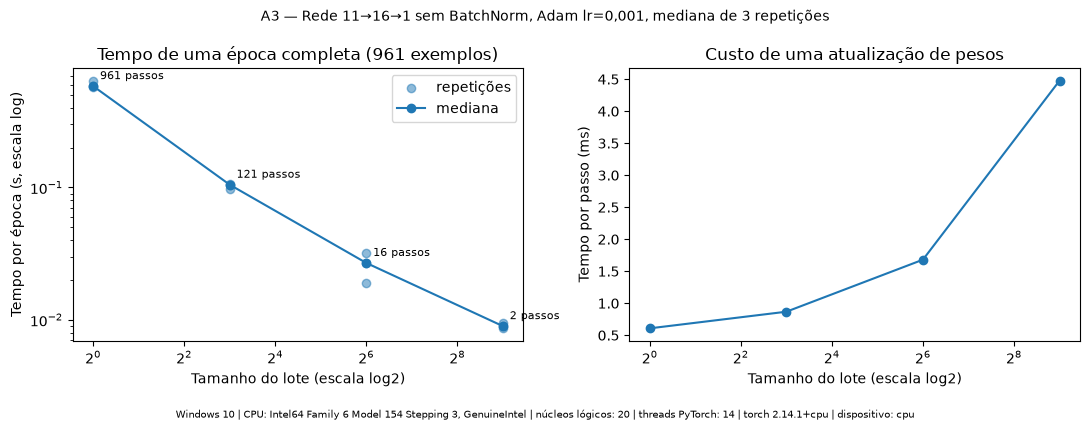

In [10]:
import platform, os

# Descrição do equipamento (exigida junto do gráfico)
equipamento = (f"{platform.system()} {platform.release()} | CPU: {platform.processor()} | "
               f"núcleos lógicos: {os.cpu_count()} | threads PyTorch: {torch.get_num_threads()} | "
               f"torch {torch.__version__} | dispositivo: {DISPOSITIVO}")
print(equipamento)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Esquerda: tempo por época (pontos = repetições; linha = mediana), eixos em escala log
ax1.scatter(df_tempos['batch_size'], df_tempos['segundos'], alpha=0.5, label='repetições')
ax1.plot(resumo_a3['batch_size'], resumo_a3['mediana_s'], marker='o', label='mediana')
for _, r in resumo_a3.iterrows():
    ax1.annotate(f"{int(r['passos'])} passos", (r['batch_size'], r['mediana_s']),
                 textcoords='offset points', xytext=(5, 5), fontsize=8)
ax1.set_xscale('log', base=2); ax1.set_yscale('log')
ax1.set_xlabel('Tamanho do lote (escala log2)'); ax1.set_ylabel('Tempo por época (s, escala log)')
ax1.set_title('Tempo de uma época completa (961 exemplos)'); ax1.legend()

# Direita: custo de cada passo (uma atualização de pesos)
ax2.plot(resumo_a3['batch_size'], resumo_a3['ms_por_passo'], marker='o')
ax2.set_xscale('log', base=2)
ax2.set_xlabel('Tamanho do lote (escala log2)'); ax2.set_ylabel('Tempo por passo (ms)')
ax2.set_title('Custo de uma atualização de pesos')

fig.suptitle(f'A3 — Rede 11→16→1 sem BatchNorm, Adam lr=0,001, mediana de {REPETICOES} repetições',
             fontsize=10)
fig.text(0.5, -0.04, equipamento, ha='center', fontsize=7)
fig.tight_layout()
fig.savefig(RESULTADOS / 'a3_tempo_por_lote.png', dpi=150, bbox_inches='tight')
plt.show()

## A4. BatchNorm com último lote 1
Use um subconjunto de 65 observações do treino e lote 64, ou outra condição equivalente. Confirme o resto. Use `criar_modelo(11, batchnorm=True)`, modo de treino e `drop_last=False`. Capture especificamente o erro esperado, mostre sua mensagem e depois execute a correção que escolheu. Preserve as outras partes do notebook.

In [11]:
# ---------- Montagem: 65 observações APENAS do treino, lote 64 ----------
N_SUB, LOTE_A4 = 65, 64
idx_sub = torch.randperm(len(ds_treino), generator=torch.Generator().manual_seed(SEED))[:N_SUB]
ds_sub_a4 = Subset(ds_treino, idx_sub.tolist())        # só demonstração; não substitui a base
print(f'Subconjunto: {len(ds_sub_a4)} observações | lote: {LOTE_A4} | '
      f'resto: {len(ds_sub_a4) % LOTE_A4} | lotes: {len(ds_sub_a4) // LOTE_A4} cheio(s) + 1 de tamanho 1')
assert len(ds_sub_a4) % LOTE_A4 == 1, 'A condição de resto 1 não foi satisfeita'

# Rede COM BatchNorm e estado inicial guardado (para o erro e a correção partirem do mesmo ponto)
fixar_semente(SEED)
modelo_a4 = criar_modelo(11, batchnorm=True).to(DISPOSITIVO)
estado_inicial_a4 = copy.deepcopy(modelo_a4.state_dict())
criterio_a4 = nn.BCEWithLogitsLoss()

# ---------- 1) Procedimento que FALHA: drop_last=False, modo train() ----------
loader_falha = DataLoader(ds_sub_a4, batch_size=LOTE_A4, shuffle=False, drop_last=False, num_workers=0)
print('Tamanhos dos lotes (falha):', [len(y) for _, y in loader_falha])
otimizador_a4 = torch.optim.Adam(modelo_a4.parameters(), lr=0.001)
try:
    treinar_epoca(modelo_a4, loader_falha, otimizador_a4, criterio_a4, DISPOSITIVO)  # chama modelo.train()
    print('ATENÇÃO: o erro esperado não ocorreu.')
except ValueError as erro:
    mensagem_a4 = str(erro)
    if 'Expected more than 1 value per channel' not in mensagem_a4:
        raise                                   # outro ValueError: não é o esperado, não esconder
    print('Erro capturado (ValueError):', mensagem_a4)

# ---------- 2) Correção: drop_last=True com embaralhamento ----------
modelo_a4.load_state_dict(estado_inicial_a4)                          # mesmo ponto de partida
otimizador_a4 = torch.optim.Adam(modelo_a4.parameters(), lr=0.001)    # otimizador novo
loader_corrigido = DataLoader(ds_sub_a4, batch_size=LOTE_A4, shuffle=True, drop_last=True,
                              num_workers=0, generator=torch.Generator().manual_seed(SEED))
print('\nTamanhos dos lotes (corrigido):', [len(y) for _, y in loader_corrigido])
perda_a4 = treinar_epoca(modelo_a4, loader_corrigido, otimizador_a4, criterio_a4, DISPOSITIVO)
print(f'Correção executada em modo train(): perda de treino da época = {perda_a4:.4f}')
print(f'Observações usadas por época: {len(loader_corrigido) * LOTE_A4} de {len(ds_sub_a4)} '
      f'(1 descartada; com shuffle, muda a cada época)')

Subconjunto: 65 observações | lote: 64 | resto: 1 | lotes: 1 cheio(s) + 1 de tamanho 1
Tamanhos dos lotes (falha): [64, 1]
Erro capturado (ValueError): Expected more than 1 value per channel when training, got input size torch.Size([1, 16])

Tamanhos dos lotes (corrigido): [64]
Correção executada em modo train(): perda de treino da época = 0.6502
Observações usadas por época: 64 de 65 (1 descartada; com shuffle, muda a cada época)


## C. Dois mecanismos de vazamento
Selecione duas formas; pelo menos uma entre 2/4/7 e uma com dados reais. Um caminho acessível é 1 e 2, usando a base incluída. **Formas 1–7 estão descritas no enunciado.**

Trabalhe apenas com as linhas principais de treino + validação. Crie partições internas `c_...`. Não use a partição principal de teste. Defina o modelo, a métrica e as condições antes de executar o par incorreto/corrigido. Se usar a forma 7, reserve desde o início os quatro conjuntos internos e compare seleções com orçamento igual.

In [12]:
from sklearn.metrics import roc_auc_score, log_loss

resultados_c = []

# ---------- 1) Desenvolvimento interno: SOMENTE treino + validação da B2 ----------
c_desenvolvimento = pd.concat([particoes['treino'], particoes['validacao']], ignore_index=True)
assert set(c_desenvolvimento['id_linha']).isdisjoint(particoes['teste']['id_linha']), 'Teste principal vazou para a C!'

# Divisão interna por perfil (mesma regra da B2): 75% treino interno, 25% avaliação interna
SEED_C = 2026   # semente própria da Parte C, declarada ANTES de qualquer métrica:
                # com SEED=42 a divisão interna repetia exatamente treino/validação da B2
c_gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED_C)
c_idx_tr, c_idx_av = next(c_gss.split(c_desenvolvimento, groups=c_desenvolvimento['grupo_perfil']))
c_treino = c_desenvolvimento.iloc[c_idx_tr].reset_index(drop=True)
c_avaliacao = c_desenvolvimento.iloc[c_idx_av].reset_index(drop=True)
assert set(c_treino['grupo_perfil']).isdisjoint(c_avaliacao['grupo_perfil'])

for nome, p in [('c_desenvolvimento', c_desenvolvimento), ('c_treino', c_treino), ('c_avaliacao', c_avaliacao)]:
    print(f"{nome:18s} linhas={len(p):5d} | positivos={int(p['alvo'].sum()):4d} "
          f"({p['alvo'].mean():.3f}) | perfis={p['grupo_perfil'].nunique()}")
print('Teste principal intocado:', len(particoes['teste']), 'linhas fora da Parte C')

# ---------- 2) Protocolo fixado ANTES de comparar ----------
C_EPOCAS = 50                          # fixo: sem parada antecipada (evita usar c_avaliacao para escolher)
C_LOTE = 64
C_LR = 0.001
C_SEMENTES = [42, 7, 123, 2024, 31415] # declaradas agora; TODAS serão relatadas
# Métrica principal: AUC-ROC em c_avaliacao (maior = melhor). Secundária: perda log (menor = melhor).

def c_treinar(ds_tr, semente):
    """Treina a rede de apoio n->16->1 (sem BatchNorm) por C_EPOCAS épocas fixas;
    n = número de colunas de entrada do Dataset (11 no correto)."""
    fixar_semente(semente)
    modelo = criar_modelo(ds_tr.X.shape[1]).to(DISPOSITIVO)
    otim = torch.optim.Adam(modelo.parameters(), lr=C_LR)
    loader = DataLoader(ds_tr, batch_size=C_LOTE, shuffle=True, drop_last=False, num_workers=0,
                        generator=torch.Generator().manual_seed(semente))
    for _ in range(C_EPOCAS):
        treinar_epoca(modelo, loader, otim, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    return modelo

def c_avaliar(modelo, ds_av):
    """Devolve (AUC-ROC, perda log) do modelo no conjunto de avaliação interna."""
    loader = DataLoader(ds_av, batch_size=256, shuffle=False, drop_last=False, num_workers=0)
    rotulos, escores = obter_escores(modelo, loader, DISPOSITIVO)
    return roc_auc_score(rotulos, escores), log_loss(rotulos, escores, labels=[0, 1])

print('\nProtocolo:', f'{C_EPOCAS} épocas, lote {C_LOTE}, Adam lr={C_LR}, sementes {C_SEMENTES}')

c_desenvolvimento  linhas= 1279 | positivos= 172 (0.134) | perfis=1087
c_treino           linhas=  959 | positivos= 123 (0.128) | perfis=815
c_avaliacao        linhas=  320 | positivos=  49 (0.153) | perfis=272
Teste principal intocado: 320 linhas fora da Parte C

Protocolo: 50 épocas, lote 64, Adam lr=0.001, sementes [42, 7, 123, 2024, 31415]


In [13]:
# ===================== FORMA 1: pré-processamento com dados reservados =====================
# Informação protegida: a distribuição das características em c_avaliacao.
# Onde atravessa: no cálculo de média/desvio, ANTES do treino.

# --- INCORRETO: estatísticas aprendidas com c_treino + c_avaliacao (c_desenvolvimento inteiro) ---
c1_estat_errado = MeuDataset(c_desenvolvimento, FEATURES)    # usado só para extrair média/desvio
c1_tr_errado = MeuDataset(c_treino, FEATURES, media=c1_estat_errado.media, desvio=c1_estat_errado.desvio)
c1_av_errado = MeuDataset(c_avaliacao, FEATURES, media=c1_estat_errado.media, desvio=c1_estat_errado.desvio)

# --- CORRIGIDO: estatísticas aprendidas SÓ com c_treino e repassadas à avaliação ---
c1_tr_certo = MeuDataset(c_treino, FEATURES)
c1_av_certo = MeuDataset(c_avaliacao, FEATURES, media=c1_tr_certo.media, desvio=c1_tr_certo.desvio)

# Tamanho da contaminação: quanto as estatísticas mudaram (em unidades do desvio correto)
c1_dif_media = np.abs(c1_estat_errado.media - c1_tr_certo.media) / c1_tr_certo.desvio
c1_dif_desvio = np.abs(c1_estat_errado.desvio / c1_tr_certo.desvio - 1)
print(f'Maior mudança na média: {c1_dif_media.max():.3f} desvio ({FEATURES[c1_dif_media.argmax()]})')
print(f'Maior mudança no desvio: {100*c1_dif_desvio.max():.1f}% ({FEATURES[c1_dif_desvio.argmax()]})')

# --- Execução pareada: mesma semente => mesmos pesos iniciais e mesmo embaralhamento ---
c1_linhas = []
for s in C_SEMENTES:
    auc_e, ll_e = c_avaliar(c_treinar(c1_tr_errado, s), c1_av_errado)
    auc_c, ll_c = c_avaliar(c_treinar(c1_tr_certo, s), c1_av_certo)
    c1_linhas.append({'semente': s, 'auc_incorreto': auc_e, 'auc_corrigido': auc_c,
                      'll_incorreto': ll_e, 'll_corrigido': ll_c})
c1_df = pd.DataFrame(c1_linhas)
c1_df['dif_auc_pp'] = 100 * (c1_df['auc_incorreto'] - c1_df['auc_corrigido'])
c1_df['dif_logloss'] = c1_df['ll_incorreto'] - c1_df['ll_corrigido']
print('\n', c1_df.round(4).to_string(index=False))

# --- Resumo: efeito médio x variação natural entre sementes ---
print(f"\nAUC média  incorreto={c1_df.auc_incorreto.mean():.4f} | corrigido={c1_df.auc_corrigido.mean():.4f}")
print(f"Diferença AUC (pp): média={c1_df.dif_auc_pp.mean():+.3f} | "
      f"mín={c1_df.dif_auc_pp.min():+.3f} | máx={c1_df.dif_auc_pp.max():+.3f}")
print(f"Variação natural da AUC corrigida entre sementes (desvio-padrão): "
      f"{100*c1_df.auc_corrigido.std():.3f} pp")
print(f"Sementes em que o incorreto superou o corrigido: {(c1_df.dif_auc_pp > 0).sum()} de {len(c1_df)}")

resultados_c.append({'forma': 1, 'fonte': 'Wine Quality real (c_treino/c_avaliacao)',
                     'metrica': 'AUC-ROC em c_avaliacao, média de 5 sementes',
                     'incorreto': c1_df.auc_incorreto.mean(), 'corrigido': c1_df.auc_corrigido.mean(),
                     'diferenca': c1_df.dif_auc_pp.mean(), 'unidade': 'pontos percentuais de AUC'})
c1_df.to_csv(RESULTADOS / 'c_forma1_sementes.csv', index=False)

Maior mudança na média: 0.027 desvio (total sulfur dioxide)
Maior mudança no desvio: 4.4% (chlorides)

  semente  auc_incorreto  auc_corrigido  ll_incorreto  ll_corrigido  dif_auc_pp  dif_logloss
      42         0.8382         0.8387        0.3234        0.3234     -0.0452      -0.0000
       7         0.8471         0.8483        0.3200        0.3198     -0.1280       0.0002
     123         0.8349         0.8344        0.3292        0.3292      0.0452      -0.0000
    2024         0.8506         0.8498        0.3153        0.3153      0.0828      -0.0000
   31415         0.8469         0.8479        0.3199        0.3188     -0.0979       0.0011

AUC média  incorreto=0.8435 | corrigido=0.8438
Diferença AUC (pp): média=-0.029 | mín=-0.128 | máx=+0.083
Variação natural da AUC corrigida entre sementes (desvio-padrão): 0.684 pp
Sementes em que o incorreto superou o corrigido: 2 de 5


In [14]:
# ===================== FORMA 2: alvo (ou derivado) entre as características =====================
# Informação protegida: a nota sensorial 'quality', da qual o alvo é derivado (alvo = quality >= 7).
# Onde atravessa: na montagem da matriz de entradas, antes do treino.

# Proteção existente: o MeuDataset recusa a coluna pelo NOME
try:
    MeuDataset(c_treino, FEATURES + ['quality'])
except ValueError as erro:
    print('Proteção por nome funcionou:', erro)

# --- INCORRETO (transformação declarada): cópia de 'quality' com outro nome, como 12ª entrada ---
c2_tr_df = c_treino.copy()
c2_av_df = c_avaliacao.copy()
c2_tr_df['nota_sensorial'] = c2_tr_df['quality']      # mesma informação, nome diferente
c2_av_df['nota_sensorial'] = c2_av_df['quality']
FEATURES_C2_ERRADO = FEATURES + ['nota_sensorial']

c2_tr_errado = MeuDataset(c2_tr_df, FEATURES_C2_ERRADO)       # normalização só no treino interno
c2_av_errado = MeuDataset(c2_av_df, FEATURES_C2_ERRADO,
                          media=c2_tr_errado.media, desvio=c2_tr_errado.desvio)
print('Renomeada passou pela proteção; entradas no incorreto:', c2_tr_errado.X.shape[1])

# Mecanismo: a regra nota_sensorial >= 7 reproduz o alvo em 100% das linhas
print('Regra nota_sensorial >= 7 igual ao alvo em c_avaliacao:',
      f"{((c2_av_df['nota_sensorial'] >= 7).astype(int) == c2_av_df['alvo']).mean():.1%}")

# --- CORRIGIDO: apenas as 11 características (os mesmos datasets corretos da forma 1) ---
c2_linhas = []
for s in C_SEMENTES:
    auc_e, ll_e = c_avaliar(c_treinar(c2_tr_errado, s), c2_av_errado)
    auc_c, ll_c = c_avaliar(c_treinar(c1_tr_certo, s), c1_av_certo)
    c2_linhas.append({'semente': s, 'auc_incorreto': auc_e, 'auc_corrigido': auc_c,
                      'll_incorreto': ll_e, 'll_corrigido': ll_c})
c2_df = pd.DataFrame(c2_linhas)
c2_df['dif_auc_pp'] = 100 * (c2_df['auc_incorreto'] - c2_df['auc_corrigido'])
c2_df['dif_logloss'] = c2_df['ll_incorreto'] - c2_df['ll_corrigido']
print('\n', c2_df.round(4).to_string(index=False))

# Conferência de reprodutibilidade: o corrigido daqui deve ser idêntico ao corrigido da forma 1
print('\nCorrigido idêntico ao da forma 1:', np.allclose(c2_df.auc_corrigido, c1_df.auc_corrigido))

print(f"AUC média  incorreto={c2_df.auc_incorreto.mean():.4f} | corrigido={c2_df.auc_corrigido.mean():.4f}")
print(f"Diferença AUC (pp): média={c2_df.dif_auc_pp.mean():+.3f} | "
      f"mín={c2_df.dif_auc_pp.min():+.3f} | máx={c2_df.dif_auc_pp.max():+.3f}")
print(f"Perda log média  incorreto={c2_df.ll_incorreto.mean():.4f} | corrigido={c2_df.ll_corrigido.mean():.4f}")

resultados_c.append({'forma': 2, 'fonte': 'Wine Quality real (c_treino/c_avaliacao)',
                     'metrica': 'AUC-ROC em c_avaliacao, média de 5 sementes',
                     'incorreto': c2_df.auc_incorreto.mean(), 'corrigido': c2_df.auc_corrigido.mean(),
                     'diferenca': c2_df.dif_auc_pp.mean(), 'unidade': 'pontos percentuais de AUC'})
c2_df.to_csv(RESULTADOS / 'c_forma2_sementes.csv', index=False)

Proteção por nome funcionou: Features contém colunas proibidas (alvo ou identificadores).
Renomeada passou pela proteção; entradas no incorreto: 12
Regra nota_sensorial >= 7 igual ao alvo em c_avaliacao: 100.0%

  semente  auc_incorreto  auc_corrigido  ll_incorreto  ll_corrigido  dif_auc_pp  dif_logloss
      42         0.9986         0.8387        0.0692        0.3234     15.9876      -0.2542
       7         0.9947         0.8483        0.0968        0.3198     14.6397      -0.2230
     123         0.9999         0.8344        0.0746        0.3292     16.5525      -0.2546
    2024         0.9873         0.8498        0.1094        0.3153     13.7510      -0.2059
   31415         0.9982         0.8479        0.0707        0.3188     15.0313      -0.2481

Corrigido idêntico ao da forma 1: True
AUC média  incorreto=0.9957 | corrigido=0.8438
Diferença AUC (pp): média=+15.192 | mín=+13.751 | máx=+16.552
Perda log média  incorreto=0.0841 | corrigido=0.3213


## D7. Rede principal com parada antecipada
Construa uma rede nova; não reutilize os pesos ou estatísticas do experimento incorreto da Parte C. A arquitetura de apoio pode ser usada. Complete o laço: treinar, avaliar validação, comparar melhora, copiar o melhor estado, contar paciência, parar e restaurar. Use `copy.deepcopy(modelo.state_dict())` ou tensores clonados para guardar uma cópia independente.

Não forneça o loader de teste à função de treinamento. A perda de validação seleciona a época; o teste não aparece no histórico.

In [15]:
def treinar_com_parada(modelo, loader_treino, loader_validacao,
                       max_epocas=100, paciencia=10, min_delta=0.0001, lr=0.001):
    """Treina com parada antecipada monitorando a PERDA DE VALIDAÇÃO.

    A cada época: treina, avalia a validação sem gradientes, verifica melhora
    (perda < melhor_perda - min_delta), guarda cópia independente dos pesos
    quando melhora e conta épocas sem melhora. Para ao atingir a paciência
    ou o máximo de épocas e RESTAURA os melhores pesos antes de retornar.
    O loader de teste NÃO é parâmetro: o teste não participa do treino.

    Retorna dict com: historico (DataFrame), melhor_epoca, epoca_final,
    melhor_perda e motivo_parada ('paciencia' ou 'max_epocas').
    """
    criterio = nn.BCEWithLogitsLoss()                         # sem ponderação de classes
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

    melhor_perda, melhor_epoca, melhor_estado = float('inf'), 0, None
    epocas_sem_melhora, motivo = 0, 'max_epocas'
    historico = []

    for epoca in range(1, max_epocas + 1):
        perda_tr = treinar_epoca(modelo, loader_treino, otimizador, criterio, DISPOSITIVO)
        perda_val = avaliar_perda(modelo, loader_validacao, criterio, DISPOSITIVO)  # sem gradientes

        melhorou = perda_val < melhor_perda - min_delta
        if melhorou:
            melhor_perda, melhor_epoca = perda_val, epoca
            melhor_estado = copy.deepcopy(modelo.state_dict())   # FOTOCÓPIA, não referência
            epocas_sem_melhora = 0
        else:
            epocas_sem_melhora += 1

        historico.append({'epoca': epoca, 'perda_treino': perda_tr, 'perda_validacao': perda_val,
                          'melhorou': melhorou, 'epocas_sem_melhora': epocas_sem_melhora})

        if epocas_sem_melhora >= paciencia:
            motivo = 'paciencia'
            break

    modelo.load_state_dict(melhor_estado)                     # RESTAURA o melhor estado
    return {'historico': pd.DataFrame(historico), 'melhor_epoca': melhor_epoca,
            'epoca_final': epoca, 'melhor_perda': melhor_perda, 'motivo_parada': motivo}


# ---------- Rede principal NOVA (nada herdado da Parte C nem da A4) ----------
fixar_semente(SEED)
gerador_treino.manual_seed(SEED)              # embaralhamento do loader_treino desde o início
modelo_final = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)   # 11 -> 16 -> 1, ReLU

D7_CONFIG = {'max_epocas': 100, 'paciencia': 10, 'min_delta': 0.0001, 'lr': 0.001}
resultado_d7 = treinar_com_parada(modelo_final, loader_treino, loader_validacao, **D7_CONFIG)
historico = resultado_d7['historico']

print(f"Configuração: {D7_CONFIG}")
print(f"Motivo da parada: {resultado_d7['motivo_parada']} | época final: {resultado_d7['epoca_final']} "
      f"| melhor época: {resultado_d7['melhor_epoca']} | melhor perda de validação: {resultado_d7['melhor_perda']:.5f}")

# ---------- Confirmação da restauração ----------
perda_val_restaurado = avaliar_perda(modelo_final, loader_validacao, nn.BCEWithLogitsLoss(), DISPOSITIVO)
perda_val_ultima = historico['perda_validacao'].iloc[-1]
print(f"Perda de validação do modelo restaurado: {perda_val_restaurado:.5f} "
      f"(última época: {perda_val_ultima:.5f})")
assert abs(perda_val_restaurado - resultado_d7['melhor_perda']) < 1e-6, 'Restauração falhou!'
print('Restauração confirmada: o modelo contém os pesos da melhor época.')

Configuração: {'max_epocas': 100, 'paciencia': 10, 'min_delta': 0.0001, 'lr': 0.001}
Motivo da parada: paciencia | época final: 57 | melhor época: 47 | melhor perda de validação: 0.26885
Perda de validação do modelo restaurado: 0.26885 (última época: 0.26976)
Restauração confirmada: o modelo contém os pesos da melhor época.


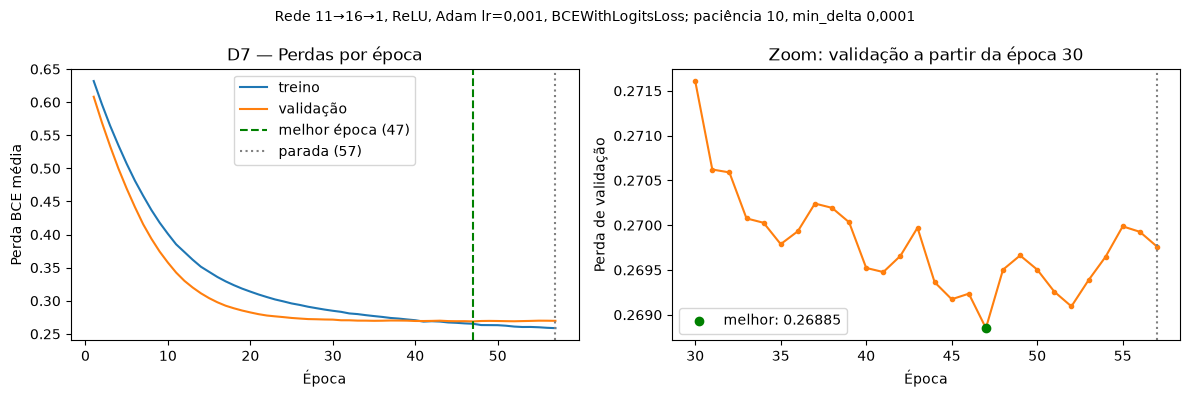

Primeiras e últimas épocas:
 epoca  perda_treino  perda_validacao  melhorou  epocas_sem_melhora
     1       0.63192          0.60820      True                   0
     2       0.59673          0.56919      True                   0
     3       0.56419          0.53329      True                   0
    46       0.26590          0.26924     False                   1
    47       0.26534          0.26885      True                   0
    48       0.26337          0.26950     False                   1
    49       0.26329          0.26966     False                   2
    50       0.26319          0.26950     False                   3
    51       0.26239          0.26926     False                   4
    52       0.26109          0.26909     False                   5
    53       0.26045          0.26939     False                   6
    54       0.26052          0.26965     False                   7
    55       0.26003          0.26999     False                   8
    56       0.25922

In [16]:
melhor = resultado_d7['melhor_epoca']
final = resultado_d7['epoca_final']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Esquerda: curvas completas de treino e validação
ax1.plot(historico['epoca'], historico['perda_treino'], label='treino')
ax1.plot(historico['epoca'], historico['perda_validacao'], label='validação')
ax1.axvline(melhor, color='green', ls='--', label=f'melhor época ({melhor})')
ax1.axvline(final, color='gray', ls=':', label=f'parada ({final})')
ax1.set_xlabel('Época'); ax1.set_ylabel('Perda BCE média')
ax1.set_title('D7 — Perdas por época'); ax1.legend()

# Direita: zoom na validação a partir da época 30 (onde a melhora fica pequena)
zoom = historico[historico['epoca'] >= 30]
ax2.plot(zoom['epoca'], zoom['perda_validacao'], marker='.', color='tab:orange')
ax2.scatter([melhor], [resultado_d7['melhor_perda']], color='green', zorder=3,
            label=f'melhor: {resultado_d7["melhor_perda"]:.5f}')
ax2.axvline(final, color='gray', ls=':')
ax2.set_xlabel('Época'); ax2.set_ylabel('Perda de validação')
ax2.set_title('Zoom: validação a partir da época 30'); ax2.legend()

fig.suptitle('Rede 11→16→1, ReLU, Adam lr=0,001, BCEWithLogitsLoss; paciência 10, min_delta 0,0001',
             fontsize=10)
fig.tight_layout()
fig.savefig(RESULTADOS / 'd7_curvas_perda.png', dpi=150, bbox_inches='tight')
plt.show()

historico.to_csv(RESULTADOS / 'd7_historico.csv', index=False)
print('Primeiras e últimas épocas:')
print(pd.concat([historico.head(3), historico.tail(12)]).round(5).to_string(index=False))

## D4. Custos como hipóteses explícitas
Descreva a ação de selecionar uma amostra como alta nota. Defina custos positivos de falso positivo e falso negativo, uma unidade e uma justificativa. Não existem custos reais no CSV. Acertos custam zero na simplificação deste laboratório.

In [17]:
# ---------- D4: custos como HIPÓTESES EXPLÍCITAS do exercício ----------
# Ação apoiada: previsão positiva => ENVIAR a amostra para análise especial (painel de especialistas);
#               previsão negativa => NÃO enviar (segue o fluxo comum).
# A base NÃO contém preços nem custos reais: os valores abaixo são hipotéticos.
UNIDADE_CUSTO = 'unidade de custo (1 = custo de uma análise especial)'

C_FP = 1   # FP: amostra com nota < 7 enviada à análise; o painel detecta o erro,
           #     e a perda se limita a uma análise especial (tempo de especialistas, vaga, insumos).
C_FN = 4   # FN: amostra com nota >= 7 não enviada; segue como comum, perde a diferença de valor
           #     e a reputação da linha superior, e o erro não é detectado depois.
           #     Hipótese: essa perda equivale a cerca de 4 análises especiais.
# Acertos (VP e VN) custam zero nesta simplificação.

assert C_FP > 0 and C_FN > 0, 'Custos devem ser positivos'
LIMIAR_FORMULA = C_FP / (C_FP + C_FN)

def custo_total(y_real, y_previsto, c_fp=C_FP, c_fn=C_FN):
    """Custo = C_FP x nº de falsos positivos + C_FN x nº de falsos negativos."""
    y_real, y_previsto = np.asarray(y_real), np.asarray(y_previsto)
    fp = int(((y_previsto == 1) & (y_real == 0)).sum())
    fn = int(((y_previsto == 0) & (y_real == 1)).sum())
    return c_fp * fp + c_fn * fn, fp, fn

print(f'C_FP = {C_FP} | C_FN = {C_FN} | unidade: {UNIDADE_CUSTO}')
print(f'Razão C_FN/C_FP = {C_FN/C_FP:.0f} | limiar teórico (fórmula, só para comparação na D6) = {LIMIAR_FORMULA:.2f}')

# Teste rápido da função com um exemplo inventado: 2 FP e 1 FN => 2*1 + 1*4 = 6
print('Teste da função de custo:', custo_total([0, 0, 1, 1, 0], [1, 1, 0, 1, 0]))

C_FP = 1 | C_FN = 4 | unidade: unidade de custo (1 = custo de uma análise especial)
Razão C_FN/C_FP = 4 | limiar teórico (fórmula, só para comparação na D6) = 0.20
Teste da função de custo: (6, 2, 1)


## D5 e D6. Escolha na validação e fórmula
Use `obter_escores(modelo_final, loader_validacao, DISPOSITIVO)` após a restauração. Compare limiares usando os rótulos da validação. Inclua os casos extremos; registre regra de empate ou resolução de uma grade. Compare com 0,5 e com `C_FP/(C_FP+C_FN)`. Investigue calibração sem transformar sigmoide em garantia de probabilidade.

Salve modelo, normalização, lista de entradas, custos e limiar como escolhas fixadas antes da próxima seção.

In [18]:
# ---------- Escores da VALIDAÇÃO com o modelo restaurado (melhor época da D7) ----------
y_val, s_val = obter_escores(modelo_final, loader_validacao, DISPOSITIVO)   # alinhados, mesma ordem
print(f'Validação: {len(y_val)} observações | positivos: {y_val.sum()} | '
      f'escores de {s_val.min():.4f} a {s_val.max():.4f} | escores únicos: {len(np.unique(s_val))}')

# ---------- Candidatos: extremos + todos os escores únicos ----------
candidatos = np.concatenate([[0.0], np.unique(s_val), [np.inf]])   # 0 => todos enviados; inf => nenhum
busca_d5 = []
for t in candidatos:
    prev = (s_val >= t).astype(int)
    custo, fp, fn = custo_total(y_val, prev)
    busca_d5.append({'limiar': float(t), 'custo': custo, 'fp': fp, 'fn': fn, 'enviados': int(prev.sum())})
busca_d5 = pd.DataFrame(busca_d5)

# ---------- Escolha: menor custo; desempate pelo MAIOR limiar (menos envios com o mesmo custo) ----------
custo_minimo = busca_d5['custo'].min()
empatados = busca_d5[busca_d5['custo'] == custo_minimo]
limiar_escolhido = float(empatados['limiar'].max())
print(f'Custo mínimo: {custo_minimo} | limiares empatados: {len(empatados)} '
      f'(de {empatados.limiar.min():.4f} a {empatados.limiar.max():.4f}) | escolhido: {limiar_escolhido:.4f}')

# ---------- Comparação de regras NA MESMA validação ----------
def resumo_regra(nome, t, y, s):
    """Matriz e custo de uma regra 'escore >= t' em (y, s)."""
    prev = (s >= t).astype(int)
    custo, fp, fn = custo_total(y, prev)
    vp = int(((prev == 1) & (y == 1)).sum()); vn = int(((prev == 0) & (y == 0)).sum())
    return {'regra': nome, 'limiar': t, 'VN': vn, 'FP': fp, 'FN': fn, 'VP': vp,
            'enviados': int(prev.sum()), 'custo_total': custo, 'custo_por_obs': custo / len(y)}

comparacao_val = pd.DataFrame([
    resumo_regra('Nenhum enviado (extremo)', np.inf, y_val, s_val),
    resumo_regra('Todos enviados (extremo)', 0.0, y_val, s_val),
    resumo_regra('Padrão 0,5', 0.5, y_val, s_val),
    resumo_regra('Fórmula C_FP/(C_FP+C_FN)', LIMIAR_FORMULA, y_val, s_val),
    resumo_regra('Escolhido na validação', limiar_escolhido, y_val, s_val),
])
print('\n', comparacao_val.round(4).to_string(index=False))

busca_d5.to_csv(RESULTADOS / 'd5_busca_limiar_validacao.csv', index=False)
comparacao_val.to_csv(RESULTADOS / 'd5_comparacao_validacao.csv', index=False)

Validação: 318 observações | positivos: 33 | escores de 0.0016 a 0.7885 | escores únicos: 272
Custo mínimo: 70 | limiares empatados: 1 (de 0.2562 a 0.2562) | escolhido: 0.2562

                    regra  limiar  VN  FP  FN  VP  enviados  custo_total  custo_por_obs
Nenhum enviado (extremo)     inf 285   0  33   0         0          132         0.4151
Todos enviados (extremo)  0.0000   0 285   0  33       318          285         0.8962
              Padrão 0,5  0.5000 271  14  25   8        22          114         0.3585
Fórmula C_FP/(C_FP+C_FN)  0.2000 241  44   9  24        68           80         0.2516
  Escolhido na validação  0.2562 251  34   9  24        58           70         0.2201


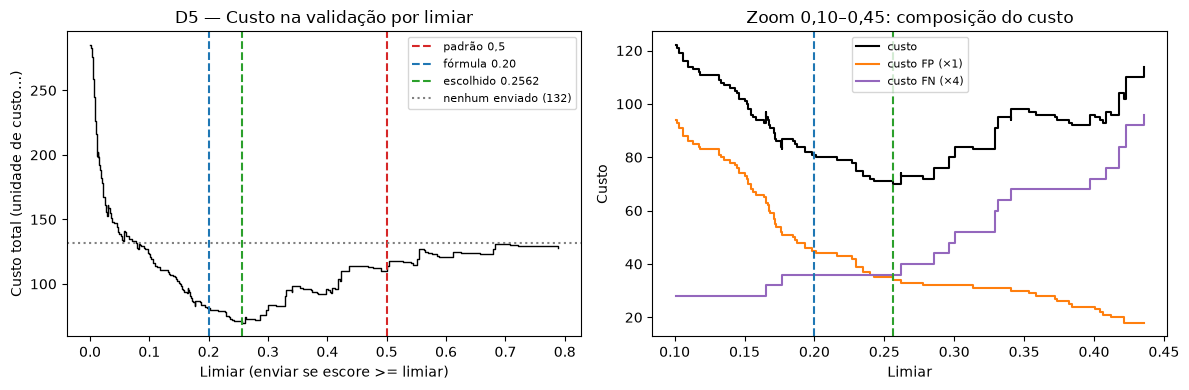

Limiares com custo até 10% acima do mínimo (70 → 77): 10 candidatos, de 0.2297 a 0.2857


In [19]:
curva = busca_d5[np.isfinite(busca_d5['limiar'])]       # remove o extremo "inf" do gráfico

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Esquerda: custo total por limiar, com as três regras marcadas
ax1.step(curva['limiar'], curva['custo'], where='post', color='black', lw=1)
for t, nome, cor in [(0.5, 'padrão 0,5', 'tab:red'),
                     (LIMIAR_FORMULA, f'fórmula {LIMIAR_FORMULA:.2f}', 'tab:blue'),
                     (limiar_escolhido, f'escolhido {limiar_escolhido:.4f}', 'tab:green')]:
    ax1.axvline(t, color=cor, ls='--', label=nome)
ax1.axhline(132, color='gray', ls=':', label='nenhum enviado (132)')
ax1.set_xlabel('Limiar (enviar se escore >= limiar)'); ax1.set_ylabel(f'Custo total ({UNIDADE_CUSTO[:16]}…)')
ax1.set_title('D5 — Custo na validação por limiar'); ax1.legend(fontsize=8)

# Direita: zoom perto do mínimo, com FP e FN separados
perto = curva[(curva['limiar'] >= 0.10) & (curva['limiar'] <= 0.45)]
ax2.step(perto['limiar'], perto['custo'], where='post', color='black', label='custo')
ax2.step(perto['limiar'], perto['fp'] * C_FP, where='post', color='tab:orange', label=f'custo FP (×{C_FP})')
ax2.step(perto['limiar'], perto['fn'] * C_FN, where='post', color='tab:purple', label=f'custo FN (×{C_FN})')
ax2.axvline(limiar_escolhido, color='tab:green', ls='--')
ax2.axvline(LIMIAR_FORMULA, color='tab:blue', ls='--')
ax2.set_xlabel('Limiar'); ax2.set_ylabel('Custo'); ax2.set_title('Zoom 0,10–0,45: composição do custo')
ax2.legend(fontsize=8)

fig.tight_layout()
fig.savefig(RESULTADOS / 'd5_curva_custo_validacao.png', dpi=150, bbox_inches='tight')
plt.show()

# Quão "largo" é o vale: limiares com custo até 10% acima do mínimo
vale = curva[curva['custo'] <= 1.10 * custo_minimo]
print(f'Limiares com custo até 10% acima do mínimo ({custo_minimo} → {1.10*custo_minimo:.0f}): '
      f'{len(vale)} candidatos, de {vale.limiar.min():.4f} a {vale.limiar.max():.4f}')

treino     prevalência real=0.145 | escore médio=0.148 | Brier=0.0814 | Brier referência (constante 0.145)=0.1237
           faixas (escore médio -> fração real): ['0.01->0.00', '0.01->0.02', '0.03->0.01', '0.08->0.08', '0.22->0.20', '0.53->0.55']
validação  prevalência real=0.104 | escore médio=0.131 | Brier=0.0805 | Brier referência (constante 0.145)=0.0947
           faixas (escore médio -> fração real): ['0.01->0.00', '0.01->0.02', '0.03->0.06', '0.08->0.06', '0.19->0.09', '0.48->0.40']


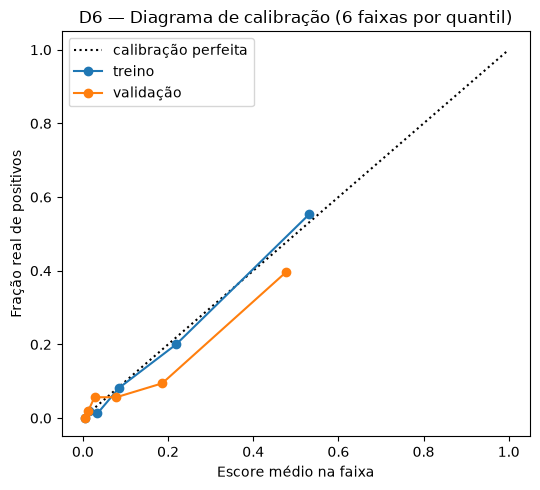

In [20]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Escores do TREINO com um loader SEM embaralhar (só para diagnóstico de calibração)
loader_treino_aval = DataLoader(ds_treino, batch_size=256, shuffle=False, drop_last=False, num_workers=0)
y_tr, s_tr = obter_escores(modelo_final, loader_treino_aval, DISPOSITIVO)

prev_treino = y_tr.mean()                     # prevalência aprendida (referência ingênua)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], 'k:', label='calibração perfeita')
for nome, y, s in [('treino', y_tr, s_tr), ('validação', y_val, s_val)]:
    frac_pos, escore_medio = calibration_curve(y, s, n_bins=6, strategy='quantile')
    ax.plot(escore_medio, frac_pos, marker='o', label=nome)
    brier = brier_score_loss(y, s)
    brier_ref = brier_score_loss(y, np.full(len(y), prev_treino))
    print(f'{nome:10s} prevalência real={y.mean():.3f} | escore médio={s.mean():.3f} | '
          f'Brier={brier:.4f} | Brier referência (constante {prev_treino:.3f})={brier_ref:.4f}')
    print('           faixas (escore médio -> fração real):',
          [f'{e:.2f}->{f:.2f}' for e, f in zip(escore_medio, frac_pos)])
ax.set_xlabel('Escore médio na faixa'); ax.set_ylabel('Fração real de positivos')
ax.set_title('D6 — Diagrama de calibração (6 faixas por quantil)'); ax.legend()
fig.tight_layout()
fig.savefig(RESULTADOS / 'd6_calibracao.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
import json, hashlib

# Impressão digital dos pesos: permite provar, no teste, que o modelo não mudou após o congelamento
def impressao_pesos(modelo):
    h = hashlib.sha256()
    for nome, tensor in modelo.state_dict().items():
        h.update(nome.encode()); h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

configuracao_congelada = {
    'modelo': 'criar_modelo(11, batchnorm=False): 11 -> 16 -> 1, ReLU, saída logit',
    'treino': {**D7_CONFIG, 'otimizador': 'Adam', 'perda': 'BCEWithLogitsLoss sem ponderação',
               'lote': LOTE_TREINO, 'semente': SEED,
               'melhor_epoca': resultado_d7['melhor_epoca'], 'epoca_final': resultado_d7['epoca_final'],
               'melhor_perda_validacao': resultado_d7['melhor_perda']},
    'entradas': FEATURES,
    'normalizacao': {'origem': 'treino principal (961 linhas), ddof=0',
                     'media': ds_treino.media.tolist(), 'desvio': ds_treino.desvio.tolist()},
    'custos': {'C_FP': C_FP, 'C_FN': C_FN, 'unidade': UNIDADE_CUSTO},
    'regra_decisao': 'enviar se escore (sigmoide do logit) >= limiar',
    'limiar_escolhido': limiar_escolhido,
    'regra_desempate': 'menor custo na validação; empate -> maior limiar',
    'limiar_padrao': 0.5,
    'limiar_formula_referencia': LIMIAR_FORMULA,
    'impressao_pesos_sha256': impressao_pesos(modelo_final),
}

torch.save(modelo_final.state_dict(), RESULTADOS / 'modelo_final_state_dict.pt')
with open(RESULTADOS / 'configuracao_congelada.json', 'w', encoding='utf-8') as f:
    json.dump(configuracao_congelada, f, ensure_ascii=False, indent=2)

decisao_congelada = True
print('Configuração congelada e salva em resultados/:')
print(f"  limiar escolhido = {limiar_escolhido:.4f} | padrão = 0.5 | custos = {C_FP}/{C_FN}")
print(f"  impressão dos pesos = {configuracao_congelada['impressao_pesos_sha256'][:16]}...")
print('  decisao_congelada =', decisao_congelada)

Configuração congelada e salva em resultados/:
  limiar escolhido = 0.2562 | padrão = 0.5 | custos = 1/4
  impressão dos pesos = 33a279cc52c5462d...
  decisao_congelada = True


## D1, D2 e D3. Avaliação final
Só agora obtenha escores no teste com o modelo restaurado e decisão congelada. Avalie as duas regras já fixadas (0,5 e limiar escolhido). O baseline usa a classe majoritária **do treino**. Produza matriz com ordem `[0, 1]`, métricas, prevalência e custos.

AUC-ROC e AUC-PR usam escores. Com `precision_recall_curve`, calcule a área trapezoidal usando `auc(recall, precision)`; se reportar `average_precision_score`, chame-a AP. Na ROC, desenhe a diagonal aleatória. Na PR, desenhe a prevalência do teste.

Não use o resultado do teste para voltar à busca. Relate os limites observados.

In [22]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, precision_recall_curve, auc,
                             average_precision_score, roc_curve)

avaliacao_final = None
if not decisao_congelada:
    print('Avaliação final pendente: concluir o desenvolvimento e congelar a decisão.')
else:
    # 0) Prova de que o modelo é o mesmo congelado na D5/D6
    assert impressao_pesos(modelo_final) == configuracao_congelada['impressao_pesos_sha256'], \
        'Pesos mudaram após o congelamento!'
    print('Impressão dos pesos confere com a configuração congelada.')

    # 1) Escores do TESTE: obtidos UMA única vez
    y_teste, s_teste = obter_escores(modelo_final, loader_teste, DISPOSITIVO)
    print(f'Teste: {len(y_teste)} observações | positivos: {y_teste.sum()} | '
          f'prevalência: {y_teste.mean():.4f}')

    # 2) Métricas comuns às regras (AUCs só quando há escores)
    if True:
        prec_c, rev_c, _ = precision_recall_curve(y_teste, s_teste)
        auc_roc_rede = roc_auc_score(y_teste, s_teste)
        auc_pr_trap_rede = auc(rev_c, prec_c)                # área trapezoidal da curva PR
        ap_rede = average_precision_score(y_teste, s_teste)  # AP (não é a mesma área)

    def linha_metricas(nome, limiar_txt, pred, com_escores):
        custo, fp, fn = custo_total(y_teste, pred)
        return {'regra': nome, 'limiar': limiar_txt,
                'acuracia': accuracy_score(y_teste, pred),
                'precisao': precision_score(y_teste, pred, zero_division=0),
                'revocacao': recall_score(y_teste, pred, zero_division=0),
                'f1': f1_score(y_teste, pred, zero_division=0),
                'auc_roc': auc_roc_rede if com_escores else np.nan,
                'auc_pr_trapezoidal': auc_pr_trap_rede if com_escores else np.nan,
                'ap': ap_rede if com_escores else np.nan,
                'FP': fp, 'FN': fn, 'custo_total': custo, 'custo_por_obs': custo / len(y_teste)}

    # 3) Baseline: classe majoritária IDENTIFICADA NO TREINO (sem escore => AUCs não reportadas)
    classe_majoritaria = int(particoes['treino']['alvo'].mode()[0])
    pred_trivial = np.full(len(y_teste), classe_majoritaria)
    print(f'Classe majoritária do treino: {classe_majoritaria}')

    # 4) As duas regras JÁ FIXADAS da rede
    pred_05 = (s_teste >= 0.5).astype(int)
    pred_esc = (s_teste >= limiar_escolhido).astype(int)

    avaliacao_final = pd.DataFrame([
        linha_metricas('Trivial do treino (sempre 0)', 'não se aplica', pred_trivial, False),
        linha_metricas('Rede: padrão', '0,5', pred_05, True),
        linha_metricas('Rede: escolhido na validação', f'{limiar_escolhido:.4f}', pred_esc, True),
    ])
    print('\n', avaliacao_final.round(4).to_string(index=False))

    # 5) Matrizes de confusão: linhas = real, colunas = previsto, ordem [0, 1]
    matrizes = {}
    for nome, pred in [('padrao_0.5', pred_05), ('escolhido', pred_esc), ('trivial', pred_trivial)]:
        cm = confusion_matrix(y_teste, pred, labels=[0, 1])
        matrizes[nome] = pd.DataFrame(cm, index=['real 0', 'real 1'], columns=['previsto 0', 'previsto 1'])
        print(f'\nMatriz de confusão — {nome}:\n{matrizes[nome].to_string()}')
        matrizes[nome].to_csv(RESULTADOS / f'd2_matriz_{nome}.csv')

    avaliacao_final.to_csv(RESULTADOS / 'd2_tabela_final_teste.csv', index=False)

Impressão dos pesos confere com a configuração congelada.
Teste: 320 observações | positivos: 45 | prevalência: 0.1406
Classe majoritária do treino: 0

                        regra        limiar  acuracia  precisao  revocacao     f1  auc_roc  auc_pr_trapezoidal     ap  FP  FN  custo_total  custo_por_obs
Trivial do treino (sempre 0) não se aplica    0.8594    0.0000     0.0000 0.0000      NaN                 NaN    NaN   0  45          180         0.5625
                Rede: padrão           0,5    0.8844    0.6818     0.3333 0.4478   0.8868              0.5691 0.5769   7  30          127         0.3969
Rede: escolhido na validação        0.2562    0.8344    0.4375     0.6222 0.5138   0.8868              0.5691 0.5769  36  17          104         0.3250

Matriz de confusão — padrao_0.5:
        previsto 0  previsto 1
real 0         268           7
real 1          30          15

Matriz de confusão — escolhido:
        previsto 0  previsto 1
real 0         239          36
real 1       

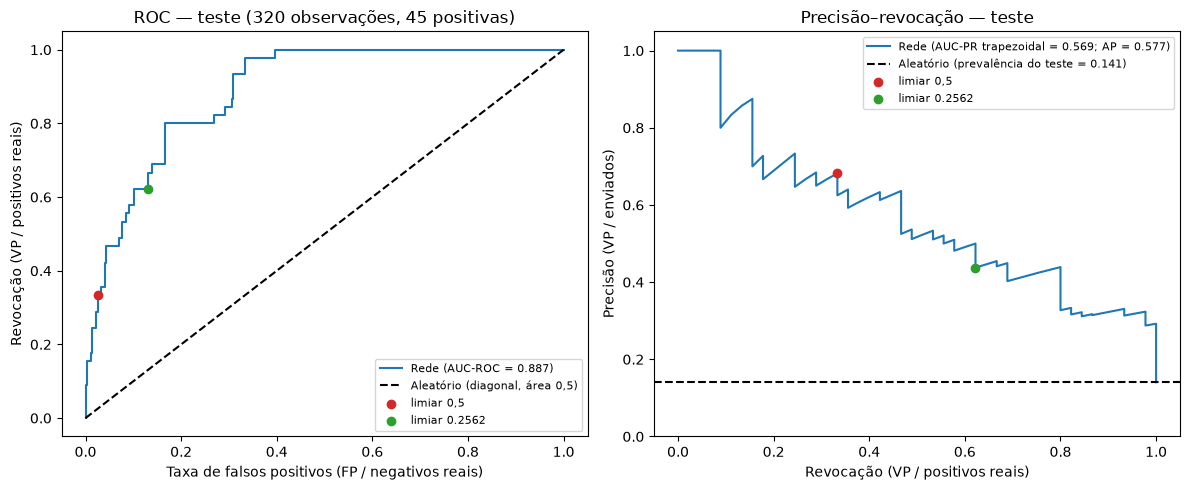

In [23]:
fpr, tpr, _ = roc_curve(y_teste, s_teste)
prev_teste = y_teste.mean()

# Pontos de operação das duas regras fixadas (onde cada limiar "fica" nas curvas)
def ponto_operacao(pred):
    cm = confusion_matrix(y_teste, pred, labels=[0, 1])
    vn, fp, fn, vp = cm.ravel()
    return fp / (fp + vn), vp / (vp + fn), (vp / (vp + fp) if vp + fp else 0.0)   # FPR, revocação, precisão

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ROC com a diagonal aleatória (área 0,5)
ax1.plot(fpr, tpr, label=f'Rede (AUC-ROC = {auc_roc_rede:.3f})')
ax1.plot([0, 1], [0, 1], 'k--', label='Aleatório (diagonal, área 0,5)')
# PR com a linha da prevalência do teste
ax2.plot(rev_c, prec_c, label=f'Rede (AUC-PR trapezoidal = {auc_pr_trap_rede:.3f}; AP = {ap_rede:.3f})')
ax2.axhline(prev_teste, color='k', ls='--', label=f'Aleatório (prevalência do teste = {prev_teste:.3f})')

for nome, pred, cor in [('limiar 0,5', pred_05, 'tab:red'),
                        (f'limiar {limiar_escolhido:.4f}', pred_esc, 'tab:green')]:
    fpr_p, rev_p, prec_p = ponto_operacao(pred)
    ax1.scatter(fpr_p, rev_p, color=cor, zorder=3, label=nome)
    ax2.scatter(rev_p, prec_p, color=cor, zorder=3, label=nome)

ax1.set_xlabel('Taxa de falsos positivos (FP / negativos reais)')
ax1.set_ylabel('Revocação (VP / positivos reais)')
ax1.set_title('ROC — teste (320 observações, 45 positivas)'); ax1.legend(loc='lower right', fontsize=8)
ax2.set_xlabel('Revocação (VP / positivos reais)'); ax2.set_ylabel('Precisão (VP / enviados)')
ax2.set_title('Precisão–revocação — teste'); ax2.legend(loc='upper right', fontsize=8)
ax2.set_ylim(0, 1.05)

fig.tight_layout()
fig.savefig(RESULTADOS / 'd3_curvas_roc_pr_teste.png', dpi=150, bbox_inches='tight')
plt.show()

## D8. Recomendação final
Escreva no README o parágrafo para quem decide: ação, limiar, evidência final, custos hipotéticos, riscos e limitações. Cite o conjunto avaliado. Não reivindique desempenho em novos produtores, regiões ou datas não observados.

## Conferência da entrega
Reinicie o kernel e execute tudo. O notebook preenchido deve mostrar as saídas de todas as partes; pendências não são resultados. Preencha o README e o arquivo obrigatório de uso de IA. Inclua as referências e registre alterações no apoio.

In [24]:
pendencias = []
for nome, valor in [('particoes', particoes), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_escolhido), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)
print('Esta checagem não corrige a análise nem substitui o checklist do enunciado.')

Pendências estruturais: []
Esta checagem não corrige a análise nem substitui o checklist do enunciado.
